# Nynorsk: overlap groups and shared passages

This is an executed, bounded review of the **full 1,028,632-document corpus**, using K = **50, 30, 20**. No fingerprint index was rebuilt for this analysis.

- **K** is a count of distinct shared, indexed fingerprints, not words or a similarity percentage.
- A **group** is a connected component of qualifying pairs. A-B-C does not imply A-C or one passage shared by everybody.
- Passage evidence uses **FingerprintChainDetector defaults**, explicit indexed pairs, stored 4-grams and winnowing window 6. No external-query top-k selection is used.
- Automatic alignment is not a human relevance label, calibrated acceptance rule, or proof of copying. All graphs remain undirected.


In [1]:
import json
import sys
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import HTML, JSON, display

WORKSPACE = Path.cwd()
if not (WORKSPACE / 'findmytext').is_dir():
    WORKSPACE = WORKSPACE.parent
if not (WORKSPACE / 'findmytext').is_dir():
    raise RuntimeError('Start this notebook from the repository root or notebooks/ directory')
assert Path(sys.prefix).resolve() == (WORKSPACE / '.venv').resolve(), 'Select the workspace .venv kernel'
if str(WORKSPACE) not in sys.path:
    sys.path.insert(0, str(WORKSPACE))
from findmytext.document_store import CorpusDocumentStore
from findmytext.overlap_groups import OverlapGroups

CORPUS = Path('/nr/project/stat/COPY.AI/data/Lars/hplt_nynorsk')
REVIEW = CORPUS / 'group_review/2026-10-26-defaults'
INDEX = CORPUS / 'findmytext_build/index'
STORE = CORPUS / 'document_store/corpus.sqlite'
report = json.loads((REVIEW / 'passage_review.json').read_text())
assert report['source_unchanged'] and report['component_verification']['status'] == 'passed'
pairs = report['pairs']
print('Kernel:', sys.executable)
print('Review:', REVIEW)
print('Every component label and degree independently checked with SciPy.')


Kernel: /nr/samba/user/lhbolsen/Repositories/CopyAI/FindMyText/.venv/bin/python
Review: /nr/project/stat/COPY.AI/data/Lars/hplt_nynorsk/group_review/2026-10-26-defaults
Every component label and degree independently checked with SciPy.


## 1. Whole-corpus results: complete groups before display limits

Singletons are accounted for but excluded from the nontrivial-group count. The largest component contains most candidate edges, so treating it as one shared passage would be misleading. The independent check covers **every edge and every document label/degree**, not just these examples.


,Candidate pairs,Documents with partners,Isolated documents,Groups (2+ documents),Largest group,Edges in largest group (%)
K,,,,,,
50,12425346,161988,866644,39299,27691,97.73
30,21685303,246275,782357,55289,48112,97.84
20,30313569,316766,711866,66445,76596,96.15


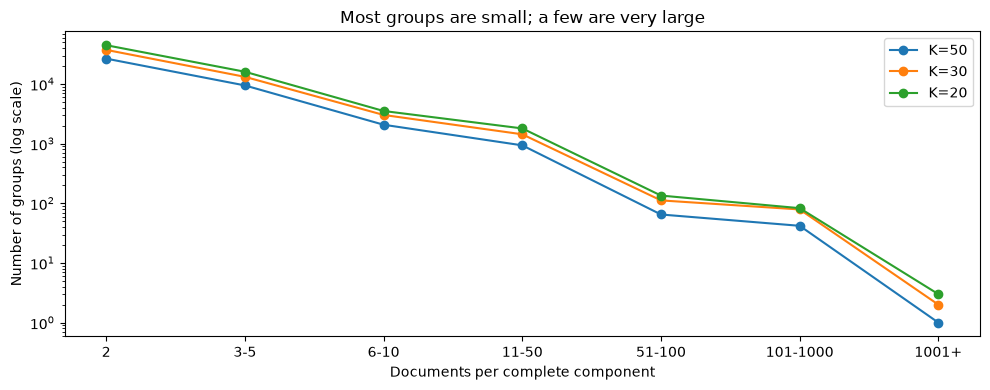

In [2]:
summary = pd.DataFrame([
    {
        'K': int(k), 'Candidate pairs': row['edges'],
        'Documents with partners': row['documents_with_partners'],
        'Isolated documents': row['isolates'],
        'Groups (2+ documents)': row['nontrivial_components'],
        'Largest group': row['largest_group_documents'],
        'Edges in largest group (%)': round(100 * row['largest_groups'][0]['edges'] / row['edges'], 2),
    } for k, row in report['components'].items()
]).sort_values('K', ascending=False).set_index('K')
display(summary)
fig, ax = plt.subplots(figsize=(10, 4))
for k, row in report['components'].items():
    bins = row['component_size_distribution']
    labels = [str(b['minimum']) if b['minimum'] == b['maximum'] else f"{b['minimum']}-{b['maximum']}" if b['maximum'] else f"{b['minimum']}+" for b in bins]
    ax.plot(labels, [b['groups'] for b in bins], marker='o', label=f'K={k}')
ax.set(yscale='log', xlabel='Documents per complete component', ylabel='Number of groups (log scale)', title='Most groups are small; a few are very large')
ax.legend()
fig.tight_layout()
plt.show()


## 2. What was reviewed, and what the defaults found

Pairs are sampled across five overlap bands and three document-size bands (the smaller full-forward fingerprint set: <100, 100-499, 500+). Eight uniformly random-priority pairs are taken per nonempty stratum. Small-group edges, bounded giant-group views and strongest-overlap pairs supplement these samples.

**Do not read the unweighted cluster rate as precision or corpus prevalence.** The supplements are purposive, the strata are unevenly populated, and no human relevance labels have been assigned. A resource-limited pair is unresolved, not a negative. Only the best surviving cluster is reported for each pair.


In [3]:
display(pd.Series(report['baseline'], name='Baseline setting').to_frame())
display(pd.Series(report['summary'], name='Reviewed sample').to_frame())
strata = pd.DataFrame(report['sampling']['strata'])
display(strata)
pair_table = pd.DataFrame([
    {
        'doc_i': p['doc_i'], 'doc_j': p['doc_j'], 'overlap': p['exact_overlap'], 'status': p['status'],
        'distinct support': (p.get('best_passage') or {}).get('distinct_fingerprint_support'),
        'span_i': (p.get('best_passage') or {}).get('token_span_i'),
        'span_j': (p.get('best_passage') or {}).get('token_span_j'),
        'longest exact token run (diagnostic)': (p.get('best_passage') or {}).get('longest_exact_token_run'),
        'has_random_selection': any(c.startswith('random:') for c in p['categories']),
    } for p in pairs
])
pair_table['overlap band'] = pd.cut(pair_table['overlap'], bins=[19, 29, 49, 99, 199, np.inf], labels=['20-29', '30-49', '50-99', '100-199', '200+'])
display(pd.crosstab(pair_table['overlap band'], pair_table['status'], dropna=False))
display(pair_table.sort_values('overlap', ascending=False).head(12))


,Baseline setting
method,rectangle
position_threshold,30
offset_threshold,30
distance_threshold,30
min_cluster_size,5
rarity_weighted,False
stored_kgram_length,4
stored_winnowing_window,6
explicit_pairs_no_top_k,True
best_surviving_cluster_only,True


,Reviewed sample
pairs,149
documents,239
cluster,148
no_cluster,0
resource_limit,1


,stratum,population,random_pairs
0,overlap_20-29__smaller_set_under100,855045,8
1,overlap_20-29__smaller_set_100-499,544321,8
2,overlap_20-29__smaller_set_500+,7228900,8
3,overlap_30-49__smaller_set_under100,517479,8
4,overlap_30-49__smaller_set_100-499,442388,8
5,overlap_30-49__smaller_set_500+,8300090,8
6,overlap_50-99__smaller_set_under100,55638,8
7,overlap_50-99__smaller_set_100-499,179272,8
8,overlap_50-99__smaller_set_500+,7972074,8
9,overlap_100-199__smaller_set_under100,0,0


status,cluster,resource_limit
overlap band,,
20-29,24,0
30-49,25,0
50-99,30,0
100-199,25,0
200+,44,1


,doc_i,doc_j,overlap,status,distinct support,span_i,span_j,longest exact token run (diagnostic),has_random_selection,overlap band
104,745295,958481,4861,resource_limit,NaN,None,None,NaN,False,200+
105,527700,971908,4256,cluster,4256.0,"[5, 15028]","[5, 15028]",NaN,False,200+
106,449417,704766,3842,cluster,3842.0,"[4, 13511]","[4, 13511]",NaN,False,200+
107,414791,924363,3815,cluster,3807.0,"[5, 13722]","[5, 13722]",NaN,False,200+
108,971650,977760,3808,cluster,3808.0,"[2, 13505]","[2, 13505]",NaN,False,200+
125,307131,311440,586,cluster,27.0,"[1567, 1651]","[983, 1067]",84.0,False,200+
103,49773,1028417,397,cluster,20.0,"[8999, 9069]","[9003, 9073]",70.0,True,200+
90,644876,1025081,378,cluster,378.0,"[1121, 2413]","[16, 1308]",1292.0,True,200+
94,34248,115732,372,cluster,256.0,"[6, 848]","[0, 842]",842.0,True,200+
99,284813,405971,365,cluster,11.0,"[985, 1020]","[11539, 11574]",35.0,True,200+


### Findings worth noticing

- **148 of 149 selected pairs have a default cluster.** The other pair exceeded the 5,000-point alignment guard and remains unresolved. All 104 stratified random examples have clusters; this is not a precision estimate.
- **Giant groups hold 96-98% of candidate links**, despite containing many fewer documents than the full corpus. A giant group is not a useful single-passage label.
- **Alignment can be uninteresting reuse.** Pair 197214/362937 matches a short `Detaljer` recommendation-list excerpt in otherwise differently titled Docplayer pages. Pair 296096/637497 matches job-ad applicant-disclosure wording. The paired evidence below makes these cases visible.
- **Repeated URLs need their own interpretation.** Ten selected pairs have the same nonempty source URL; none has byte-identical raw text. These can be crawl/version/extraction variants, not necessarily cross-site copying. Their raw provenance is preserved.
- The next useful step is **relevance calibration and content-region inspection**, not another corpus-wide fingerprint rebuild. These observations do not justify silently deleting common hashes or orienting copying arrows.


## 3. Candidate groups versus default passage support

The left plots show existing candidate edges; the right plots keep edges with a default-detector cluster and mark unresolved edges separately. Node positions are identical in each pair. Grey = candidate; green = aligned cluster; orange dotted = unresolved resource limit. Edges with no surviving cluster are omitted on the right.

First inspect **small complete components**, then **six-node induced views** around high-degree anchors in the giant components. Every displayed edge was reviewed. A split in a bounded view says nothing about connectivity through omitted documents in the full component. Green edges can still be templates or boilerplate.


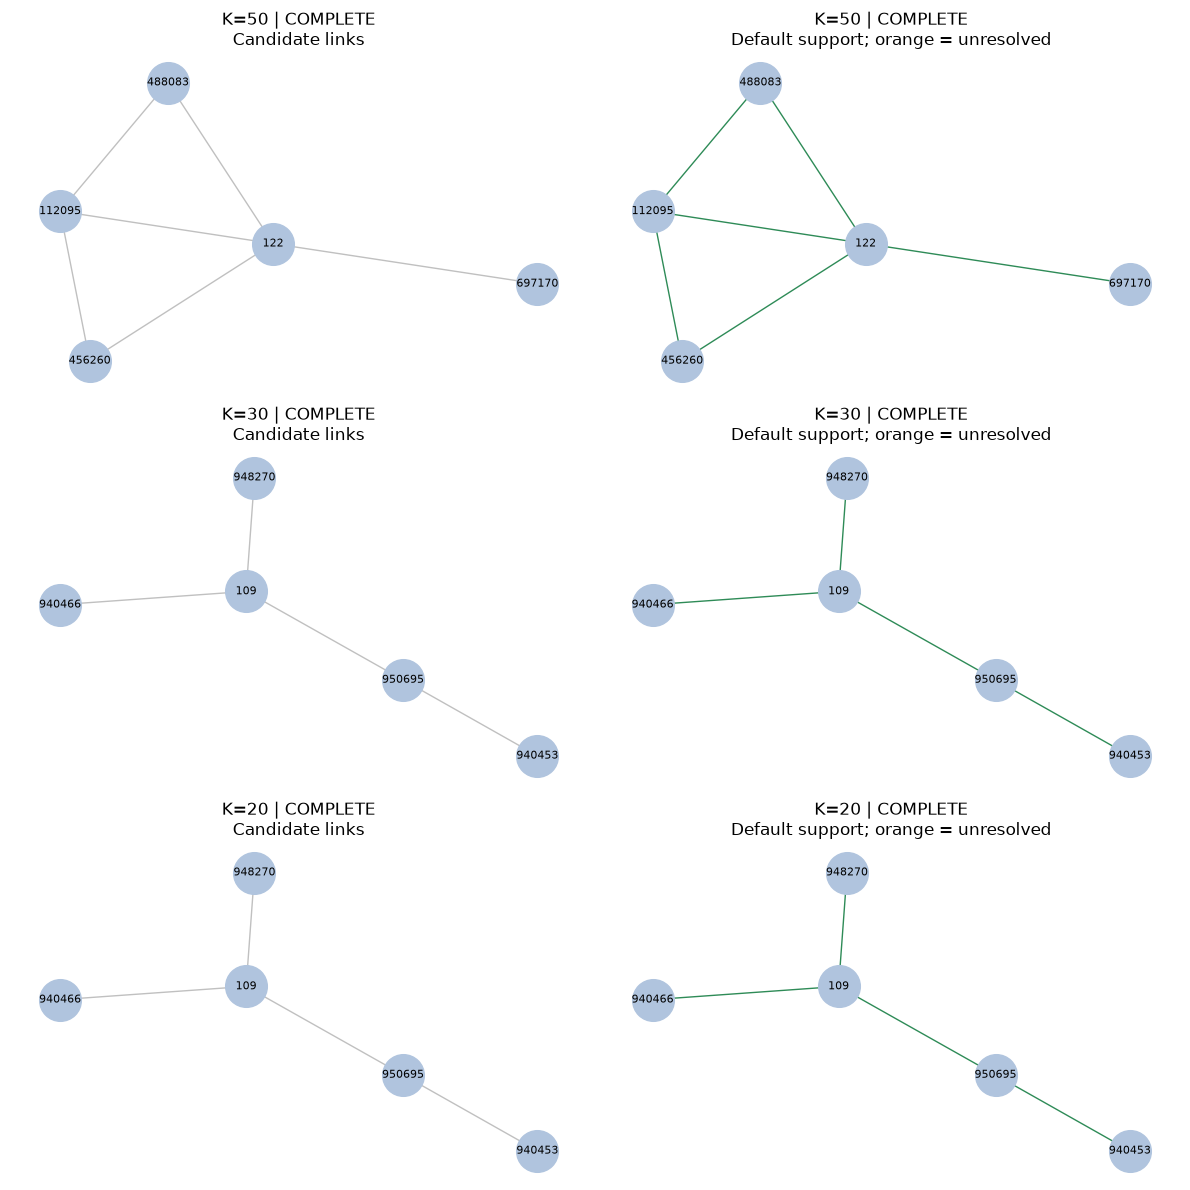

In [4]:
def draw_views(views):
    fig, axes = plt.subplots(len(views), 2, figsize=(12, 4 * len(views)), squeeze=False)
    colors = {'cluster': 'seagreen', 'resource_limit': 'darkorange'}
    styles = {'cluster': 'solid', 'resource_limit': 'dotted'}
    for row, view in enumerate(views):
        candidate = nx.Graph()
        candidate.add_nodes_from((doc, report['metadata'][str(doc)]) for doc in view['nodes'])
        candidate.add_edges_from((e['doc_i'], e['doc_j']) for e in view['edges'])
        pos = nx.spring_layout(candidate, seed=41)
        for col in (0, 1):
            ax = axes[row, col]
            nx.draw_networkx_nodes(candidate, pos, node_color='lightsteelblue', node_size=900, ax=ax)
            nx.draw_networkx_labels(candidate, pos, font_size=8, ax=ax)
            if col == 0:
                nx.draw_networkx_edges(candidate, pos, edge_color='silver', ax=ax)
            else:
                for status in ('cluster', 'resource_limit'):
                    edges = [(e['doc_i'], e['doc_j']) for e in view['edges'] if e['baseline_status'] == status]
                    nx.draw_networkx_edges(candidate, pos, edgelist=edges, edge_color=colors[status], style=styles[status], ax=ax)
            scope = 'COMPLETE' if view['complete_component'] else f"VIEW ONLY: {len(view['nodes'])} of {view['component_documents']:,} docs"
            ax.set_title(f"K={view['k']} | {scope}\n" + ('Candidate links' if col == 0 else 'Default support; orange = unresolved'))
            ax.axis('off')
    fig.tight_layout()
    plt.show()

draw_views([v for v in report['views'] if v['view_id'].endswith('small_complete')])


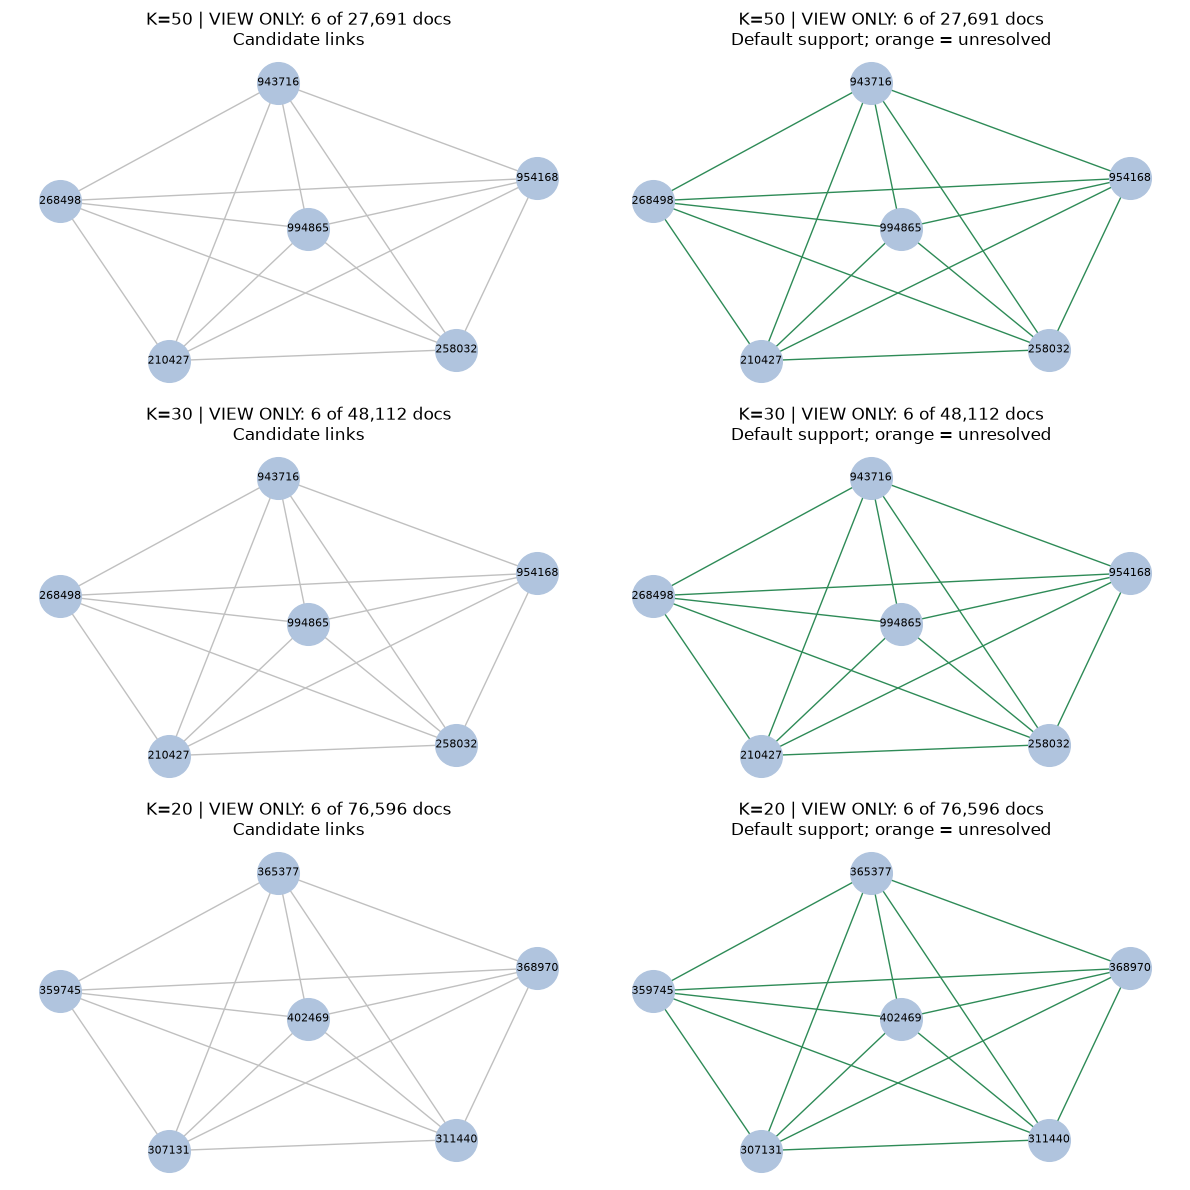

,view,full component documents,displayed documents,candidate edges,cluster edges,no-cluster edges,unresolved edges,complete component
0,k50_largest_ego,27691,6,15,15,0,0,False
1,k50_small_complete,5,5,6,6,0,0,True
2,k30_largest_ego,48112,6,15,15,0,0,False
3,k30_small_complete,5,5,4,4,0,0,True
4,k20_largest_ego,76596,6,15,15,0,0,False
5,k20_small_complete,5,5,4,4,0,0,True


In [5]:
draw_views([v for v in report['views'] if v['view_id'].endswith('largest_ego')])
display(pd.DataFrame([
    {
        'view': v['view_id'], 'full component documents': v['component_documents'],
        'displayed documents': len(v['nodes']), 'candidate edges': len(v['edges']),
        'cluster edges': sum(e['baseline_status'] == 'cluster' for e in v['edges']),
        'no-cluster edges': sum(e['baseline_status'] == 'no_cluster' for e in v['edges']),
        'unresolved edges': v['resource_limited_edges'], 'complete component': v['complete_component'],
    } for v in report['views']
]))


## 4. Read paired passage evidence

Three examples illustrate a recommendation-list excerpt, job-ad template wording, and a high-overlap same-URL pair. Previews are bounded normalized-token excerpts; token spans are zero-based, end-exclusive. Every returned aligned hash/position was checked against the original source tokens. The longest exact run is a diagnostic only, **not an extra acceptance threshold**; it is skipped for spans over 10,000 tokens. Change the example IDs or use the retrieval cell to inspect the full original text and metadata.


In [6]:
EXAMPLE_PAIRS = [(197214, 362937), (296096, 637497), (527700, 971908)]
by_pair = {(p['doc_i'], p['doc_j']): p for p in pairs}
examples = [by_pair[key] for key in EXAMPLE_PAIRS]
for p in examples:
    passage = p.get('best_passage')
    display(HTML(f"<h3>{p['doc_i']} / {p['doc_j']} | overlap {p['exact_overlap']} | {escape(p['status'])}</h3>"))
    sides = []
    for key, suffix in [('doc_i', 'i'), ('doc_j', 'j')]:
        meta = report['metadata'][str(p[key])]
        preview = passage.get('span_preview_' + suffix, '') if passage else '(No surviving default cluster; retrieve original text below.)'
        span = passage.get('token_span_' + suffix) if passage else None
        sides.append(f"<td style='width:50%;vertical-align:top'><b>{p[key]}</b><br>{escape(str(meta.get('u', '')))}<br>crawl ts: {escape(str(meta.get('ts', '')))}<br>token span: {span}<pre style='white-space:pre-wrap'>{escape(preview)}</pre></td>")
    display(HTML('<table style="table-layout:fixed;width:100%"><tr>' + ''.join(sides) + '</tr></table>'))
    if passage:
        print('Distinct support:', passage['distinct_fingerprint_support'], '| Longest exact normalized run:', passage.get('longest_exact_token_run', 'not computed'))


"197214http://docplayer.me/19153029-Saksdokument-utvalsaksnr-utval-motedato-formannskapet-kommunestyret.htmlcrawl ts: 2018-10-18T20:44:59Ztoken span: [2011, 2036]Møteinnkalling Formannskapet Utval Møtestad Kommunehuset Dato 02102014 Tidspunkt 1300 Forfall skal meldast på tlf 35 04 84 00 Varamedlemmer møter berre ved særskilt innkalling Detaljer","362937http://docplayer.me/15584795-Malet-med-lesearet-2010.htmlcrawl ts: 2018-09-21T22:02:07Ztoken span: [2395, 2420]Møteinnkalling Formannskapet Utval Møtestad Kommunehuset Dato 02102014 Tidspunkt 1300 Forfall skal meldast på tlf 35 04 84 00 Varamedlemmer møter berre ved særskilt innkalling Detaljer"


Distinct support: 7 | Longest exact normalized run: 25


"296096https://jobbsafari.no/jobb/gruppeleiar-transport-og-parkseksjonen-7412426crawl ts: 2024-07-15T14:17:20Ztoken span: [590, 614]kan bli gjort offentlege sjølv om søkjaren har oppmoda om ikkje å bli ført på søkjarlista Dersom oppmodinga ikkje blir teke til følgje skal","637497https://stilling.forskning.no/forsteamanuensis-universitetet-i-bergen-vestland/forsteamanuensis-i-moderne-historie/1712851crawl ts: 2020-08-06T17:08:18Ztoken span: [707, 731]kan bli gjort offentlege sjølv om søkjaren har oppmoda om ikkje å bli ført på søkjarlista Dersom oppmodinga ikkje blir teke til følgje skal"


Distinct support: 8 | Longest exact normalized run: 24


"527700http://docplayer.me/2863322-Vossingen-may-1950-iii.htmlcrawl ts: 2017-06-24T13:06:13Ztoken span: [5, 15028]Fyreord Det har ikkje mangla på oppfordringar til å få ut Vossingen att På dei 3 sidste Vosselagsmøti har der vore mykje snakk um den og i brev både frå Voss og vossingar her i landet har det kome fram Men det er ikkje so lika til å få noko samla skreve og prenta av slika sakor som kan vera til gagn for notid og framtid og ikkje vera for einsformigt og tungt å lesa Og det kostar mange pengar å få","971908http://docplayer.me/2863322-Vossingen-may-1950-iii.htmlcrawl ts: 2016-10-21T09:43:11Ztoken span: [5, 15028]Fyreord Det har ikkje mangla på oppfordringar til å få ut Vossingen att På dei 3 sidste Vosselagsmøti har der vore mykje snakk um den og i brev både frå Voss og vossingar her i landet har det kome fram Men det er ikkje so lika til å få noko samla skreve og prenta av slika sakor som kan vera til gagn for notid og framtid og ikkje vera for einsformigt og tungt å lesa Og det kostar mange pengar å få"


Distinct support: 4256 | Longest exact normalized run: not computed


## 5. Efficient batch retrieval: full JSON or metadata only

The new SQLite store is built with one initial scan of the compressed corpus. Later lookups use the document-ID B-tree, **not a corpus scan**. Records are compressed individually, with text/XML separate so metadata-only calls need not decompress either. Original nested fields including `seg_langs`, `doc_scores` and `web-register` are retained.

Use `id_kind='internal'` for graph/index IDs and the matching index snapshot. For original corpus IDs, use string IDs with the default `id_kind='external'`. Missing or invalid IDs raise explicit errors. `get_many` returns a dict keyed by requested IDs; `iter_many` yields bounded SQL batches for larger requests.

**Direction warning:** `ts` is crawl/provenance time. It is not an established creation/publication date. Preserve it, but do not orient copying arrows from it alone.


In [7]:
display(pd.Series(report['retrieval'], name='Measured batch lookup').to_frame())
DOC_IDS = [pairs[0]['doc_i'], pairs[0]['doc_j']]
with CorpusDocumentStore(STORE, index_dir=INDEX) as store:
    docs = store.get_many(DOC_IDS, id_kind='internal')
    metadata = store.get_many(DOC_IDS, id_kind='internal', metadata_only=True)
    by_original_id = store.get_many([docs[DOC_IDS[0]]['id']])
    same_url_pairs = [p for p in pairs if report['metadata'][str(p['doc_i'])].get('u') and report['metadata'][str(p['doc_i'])].get('u') == report['metadata'][str(p['doc_j'])].get('u')]
    repeat_ids = sorted({p[key] for p in same_url_pairs for key in ('doc_i', 'doc_j')})
    repeat_docs = store.get_many(repeat_ids, id_kind='internal')
assert by_original_id[docs[DOC_IDS[0]]['id']] == docs[DOC_IDS[0]]
display(pd.DataFrame([{'internal ID': doc_id, 'original ID': doc['id'], 'URL': doc.get('u'), 'crawl ts': doc.get('ts'), 'characters': len(doc['text'])} for doc_id, doc in docs.items()]))
display(JSON(metadata[DOC_IDS[0]], expanded=False))
print('Original text preview (first 1,200 characters):\n')
print(docs[DOC_IDS[0]]['text'][:1200])
print('\nSame-URL pairs:', len(same_url_pairs), '| Identical raw text:', sum(repeat_docs[p['doc_i']]['text'] == repeat_docs[p['doc_j']]['text'] for p in same_url_pairs))
# Evaluate docs[DOC_IDS[0]] for the complete original JSON, or its ['text'] field for full text.


,Measured batch lookup
store_file,/nr/project/stat/COPY.AI/data/Lars/hplt_nynors...
raw_records,1034804
indexed_document_ids_checked,1028632
batch_documents,239
full_record_seconds,1.572703
metadata_only_seconds,0.775109
query_plan,[SEARCH documents USING INDEX sqlite_autoindex...
timing_caveat,"Local filesystem/cache observation, not a cold..."


,internal ID,original ID,URL,crawl ts,characters
0,133318,74609825d15772bba1800a10d7c6a63e,http://www.yr.no/stad/Noreg/Sogn_og_Fjordane/G...,2015-04-03T06:38:25Z,2222
1,190781,0328ab82da3bf7b8a97cffeb28469a80,http://www.yr.no/stad/Noreg/Nordland/Rana/Dund...,2014-10-15T16:06:14Z,1945


<IPython.core.display.JSON object>

Original text preview (first 1,200 characters):

Vêrvarsel forSandane lufthamn, Anda, Gloppen (Sogn og Fjordane)
Vêrsymbolet gjeld for heile perioden, temperatur- og vindvarselet er for det fyrste tidspunktet. Slik forstår du varsla på yr.no.
Snøskredvarsel
Varsel for region Fjordane
Neste oppdatering: ca 3.4. kl 16
I dag, 3.4.
I morgon, 4.4.
Tekstvarsel frå meteorologen
fredag
Sogn og Fjordane Nord og nordvest bris. Første del av dagen enkelte snøbyger på kysten og i Nordfjord, ellers oppholdsvær og perioder med sol.
laurdag
Vestlandet sør for Stad Nordlig bris, fra lørdag ettermiddag skiftende bris i Sogn og Fjordane. Opphold og lange perioder med sol.
sundag
Vestlandet sør for Stad Skiftende bris. Utover dagen litt regn, snø i indre og høyereliggende strøk. Uendret eller litt stigende temperatur.
Har varsla vore gode dei siste dagane?
100 prosent av temperaturvarsla siste tre dagar har vore gode eller svært gode.
Dei tre siste dagane har:
- 98 prosent av temperaturvarsla vore svært 

## 6. Select your own groups without rebuilding indexes

`largest` sorts by group size then stable group ID. `all_above_min` selects all groups meeting the minimum; a limit is optional and affects only the returned/displayed groups, never the previously computed corpus components. Membership arrays include all members of each component. Keep the reader open while using its memory-mapped arrays, or copy slices before closing it.


In [8]:
K = 50
with OverlapGroups(REVIEW / f'k{K}') as groups:
    selected_groups = groups.select(mode='largest', min_documents=3, limit=5)
    display(pd.DataFrame(selected_groups))
    GROUP_ID = int(selected_groups[0]['group_id'])
    preview_members = groups.members(GROUP_ID)[:10].copy()
    all_groups_at_least_5 = groups.select(mode='all_above_min', min_documents=5)
    print('Groups with at least five documents:', len(all_groups_at_least_5))
print('First ten members only, not the whole group:', preview_members.tolist())
print('Human-review worksheet:', REVIEW / 'human_review.csv')


,group_id,documents,edges,max_degree
0,0,27691,12142854,6251
1,1545,983,8490,126
2,30300,803,43174,319
3,1246,571,2509,46
4,11589,513,1788,19


Groups with at least five documents: 4368
First ten members only, not the whole group: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Human-review worksheet: /nr/project/stat/COPY.AI/data/Lars/hplt_nynorsk/group_review/2026-10-26-defaults/human_review.csv


## 7. Why is the K=50 group so large?

A follow-up investigation covers **all 27,691 member domains, all 12,142,854 component edges, all within-component fingerprint frequencies, and raw layout counts for all 20,520 Docplayer members**. A separate bounded text review samples 20 edges in each host-pair class. The tables below distinguish exact full-component measurements from sampled passage evidence.

**First, the accounting:** 866,644 documents have no partner with **at least 50** shared fingerprints. The 161,988 others form 39,299 groups of **at least two**, not three. Exactly 26,691 groups are isolated pairs (53,382 documents); the remaining 12,608 groups contain 108,606 documents in groups of size three or more.

**Main finding:** this is overwhelmingly a Docplayer edge cluster, not a Wikipedia/NRK cluster. Many raw Docplayer records contain roughly 100 short excerpts separated by standalone `Detaljer` lines, on otherwise unrelated topics. Shared excerpts create real fingerprint overlaps and real positional clusters, while being poor evidence that the named primary documents copy each other. Other Docplayer records contain ordinary document text; not every Docplayer record is a list.

**There is no common fingerprint present in all 27,691 documents.** The most frequent occurs in only 4,524 members (16.34%). Frequent hashes include specific recurring brochure/report excerpts, not only generic menu words. Different shared passages bridge different parts of the component.


In [9]:
giant = json.loads((REVIEW / 'giant-k50/report.json').read_text())
a = giant['accounting']
display(pd.DataFrame([
    {'Group size': '1: no qualifying partner', 'Groups': a['isolates'], 'Documents': a['isolates']},
    {'Group size': 'Exactly 2', 'Groups': a['exactly_two_document_groups'], 'Documents': a['documents_in_two_document_groups']},
    {'Group size': '3 or more', 'Groups': a['groups_with_at_least_three'], 'Documents': a['documents_in_groups_of_at_least_three']},
]))
domains = pd.DataFrame(giant['domains'])
domains['Share of giant documents (%)'] = (100 * domains['documents'] / giant['component']['documents']).round(2)
display(domains.head(12))
edge_classes = pd.DataFrame([{'Edge class': key, 'Edges': value, 'Share of giant edges (%)': round(100 * value / giant['component']['edges'], 3)} for key, value in giant['edge_classes'].items()])
display(edge_classes)
display(pd.Series(giant['docplayer_layout_census'], name='Exact Docplayer layout census').to_frame())
display(pd.DataFrame(giant['fingerprints']['top'])[['kgram', 'component_df', 'full_corpus_df']].head(12))
print('Distinct source hosts:', len(domains))
print('Fingerprints present in every member:', giant['fingerprints']['present_in_every_component_document'])
print('Graph density:', f"{100 * giant['component']['density']:.2f}%", '(not a clique)')


,Group size,Groups,Documents
0,1: no qualifying partner,866644,866644
1,Exactly 2,26691,53382
2,3 or more,12608,108606


,host,documents,Share of giant documents (%)
0,docplayer.me,20520,74.10
1,www.helsetilsynet.no,585,2.11
2,www.skogholt.org,467,1.69
3,www.regjeringen.no,375,1.35
4,dittdistrikt.no,298,1.08
5,www.visitnorway.no,266,0.96
6,runeberg.org,214,0.77
7,arneberge.wordpress.com,212,0.77
8,samlaget.no,193,0.70
9,www.udir.no,163,0.59


,Edge class,Edges,Share of giant edges (%)
0,docplayer_docplayer,12095017,99.606
1,docplayer_other,5433,0.045
2,other_other,42404,0.349


,Exact Docplayer layout census
documents,20520
documents_with_at_least_3_standalone_detaljer_lines,10640
documents_with_at_least_50_standalone_detaljer_lines,10340
standalone_detaljer_lines_min_median_max,"[0.0, 93.0, 100.0]"
raw_characters_min_median_max,"[4060.0, 21461.0, 99780.0]"
interpretation,"Exact raw-text layout counts, not validated cl..."


,kgram,component_df,full_corpus_df
0,Helse Vest RHF Dato,4524,4538
1,brosjyren er det sikkert,4359,4365
2,i ein fosterheim i,4359,4369
3,allereie har flytta til,4358,4366
4,les denne brosjyren er,4358,4364
5,til ein fosterheim Det,4358,4364
6,periode eller allereie har,4358,4364
7,skal bu i ein,4358,4373
8,bur i fosterheim 1318,4357,4363
9,Om du les denne,4357,4364


Distinct source hosts: 924
Fingerprints present in every member: 0
Graph density: 3.17% (not a clique)


### Diagnostic counterfactuals, not production changes

1. **Remove Docplayer vertices:** the remaining 7,171 documents have 42,404 edges, with a largest component of 983. This is an exact induced-subgraph calculation, not a recommendation to discard all Docplayer records.
2. **Remove the 899 hashes with component document frequency >1,000, then require overlap >=50 again:** 3,762,731 edges remain (30.99%), but the largest component still has 27,654 documents. Thus a simple common-hash filter reduces density without resolving the giant-group problem. This diagnostic uses **component df**, not a full-corpus discovery cap; no production index or graph was changed.
3. **Inspect 20 sampled Docplayer-to-Docplayer edges:** all have default clusters; in 18 the best cluster starts after at least one `Detaljer` separator. For those 18, retaining only hashes before the first separator on list-like Docplayer records drops overlap below 50. This is a deliberately crude first-block-only diagnostic, **not validated primary-content extraction or a corpus-wide precision estimate**.

The evidence supports investigating **content regions and list/recommendation extraction** before raising K or banning common fingerprints. Genuine document copies and shared report templates also exist, especially among cross-host and non-Docplayer edges.


In [10]:
display(pd.DataFrame([
    {'Diagnostic': 'Original giant component', 'Documents': giant['component']['documents'], 'Edges': giant['component']['edges'], 'Largest component': giant['component']['documents']},
    {'Diagnostic': 'Induced graph without Docplayer', 'Documents': giant['without_docplayer_induced_graph']['documents'], 'Edges': giant['without_docplayer_induced_graph']['edges'], 'Largest component': giant['without_docplayer_induced_graph']['largest_components'][0]},
    {'Diagnostic': 'Subtract component-df>1000 hashes; K>=50', 'Documents': giant['common_hash_removal_diagnostic']['documents'], 'Edges': giant['common_hash_removal_diagnostic']['edges'], 'Largest component': giant['common_hash_removal_diagnostic']['largest_components'][0]},
]))
display(pd.DataFrame(giant['text_review']['by_edge_class']).T)
illustration = next(p for p in giant['text_review']['pairs'] if p['edge_class'] == 'docplayer_docplayer' and p['standalone_detaljer_lines'][0] >= 50 and p['standalone_detaljer_lines'][1] >= 50)
display(pd.DataFrame([{'Internal ID': illustration['doc_i'], 'URL': illustration['urls'][0], 'Detaljer separators': illustration['standalone_detaljer_lines'][0]}, {'Internal ID': illustration['doc_j'], 'URL': illustration['urls'][1], 'Detaljer separators': illustration['standalone_detaljer_lines'][1]}]))
print('Stored overlap:', illustration['count'], '| Default distinct cluster support:', illustration['best_passage']['distinct_fingerprint_support'])
print('Shared excerpt:', illustration['best_passage']['preview_i'])
print('Before-first-separator overlap diagnostic:', illustration['first_block_only_overlap_diagnostic'])
print('Full follow-up report:', REVIEW / 'giant-k50/report.json')


,Diagnostic,Documents,Edges,Largest component
0,Original giant component,27691,12142854,27691
1,Induced graph without Docplayer,7171,42404,983
2,Subtract component-df>1000 hashes; K>=50,27691,3762731,27654


,sampled,clusters,unresolved,below_k_after_first_block_only_diagnostic,clusters_starting_after_detaljer_in_at_least_one_doc
docplayer_docplayer,20,20,0,18,18
docplayer_other,20,20,0,0,0
other_other,20,20,0,0,0


,Internal ID,URL,Detaljer separators
0,445042,http://docplayer.me/17880473-Saksbehandling-kv...,99
1,446102,http://docplayer.me/1519411-Prosjektplan-topp-...,100


Stored overlap: 62 | Default distinct cluster support: 11
Shared excerpt: 1 I lov 17 juli 1998 nr 61 om grunnskolen og den vidaregåande opplæringa er det gjort følgende endringer endringene er markert med kursiv 212 tredje ledd skal lyde For
Before-first-separator overlap diagnostic: 0
Full follow-up report: /nr/project/stat/COPY.AI/data/Lars/hplt_nynorsk/group_review/2026-10-26-defaults/giant-k50/report.json


## 8. Interpretation and next calibration work

1. Label the reviewed examples in `human_review.csv`: substantive shared passage, template/boilerplate, navigation/reference, or unclear. Keep human labels distinct from detector status.
2. Inspect high-degree long documents and giant-group bridges; do not expand a component into every document combination or assume one common passage.
3. Only after those labels, compare passage support/span/tolerance settings on positive and negative examples. Defaults are a baseline, not an optimized production decision rule.
4. **Future experiment, noted only:** rehash selected document pairs with **winnowing window 1** to retain every 4-gram and measure whether passage coverage improves. This has **not** been run, and no all-k-gram index has been built.
5. Research trustworthy publication/creation metadata separately before proposing copying direction. Crawl timestamps and alignment alone are insufficient.

Reproduction: `experiments/review/review_overlap_groups.py`; complete component arrays and verification, passage JSON and blank human-review worksheet are in the review directory shown above. Full-corpus fingerprint indexes and the active other-language overlap queue are unchanged by this analysis.
